# 01 · Exploring the churn data

**Goal:** understand who leaves before modelling. Churn = a customer cancelled in the last month.

The dataset is a synthetic copy of the IBM *Telco Customer Churn* layout (7,043 customers, 21 columns), generated by `src/generate_data.py` so the project is fully reproducible.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 160)

In [2]:
from generate_data import generate
if not Path("data/telco_churn.csv").exists():
    Path("data").mkdir(exist_ok=True); generate().to_csv("data/telco_churn.csv", index=False)
raw = pd.read_csv("data/telco_churn.csv")
print(raw.shape); raw.head()

(7058, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,8343-LXODQ,Male,0,Yes,No,48,Yes,No,Fiber optic,Yes,...,No,No,No,No,Two year,No,Electronic check,81.85,4009.66,No
1,4107-DPLHJ,Female,0,Yes,Yes,7,Yes,Yes,DSL,Yes,...,Yes,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),76.28,520.81,No
2,7214-OBQHF,Female,0,No,No,18,Yes,Yes,Fiber optic,Yes,...,Yes,No,Yes,No,Month-to-month,Yes,Mailed check,108.03,1937.03,No
3,9716-QQNFR,Male,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,One year,No,Credit card (automatic),100.37,2910.36,No
4,3301-VWOUX,Male,0,No,No,7,Yes,No,DSL,No,...,Yes,Yes,Yes,Yes,Month-to-month,No,Credit card (automatic),85.33,599.82,Yes


## Data quality checks
Real exports are messy. Look for wrong types, blanks, duplicates and inconsistent labels.

In [3]:
print(raw.dtypes.value_counts(), "\n")
print("TotalCharges dtype:", raw.TotalCharges.dtype)
print("blank TotalCharges:", (raw.TotalCharges.astype(str).str.strip() == "").sum(),
      "| their tenure values:", raw.loc[raw.TotalCharges.astype(str).str.strip() == "", "tenure"].unique())
print("duplicate customerIDs:", raw.customerID.duplicated().sum())
print("\nPaymentMethod labels:\n", raw.PaymentMethod.value_counts())

str        18
int64       2
float64     1
Name: count, dtype: int64 

TotalCharges dtype: str
blank TotalCharges: 194 | their tenure values: [0]
duplicate customerIDs: 15

PaymentMethod labels:
 PaymentMethod
Electronic check              2353
Mailed check                  1654
Bank transfer (automatic)     1537
Credit card (automatic)       1474
electronic check                14
credit card (automatic)         11
mailed check                     9
bank transfer (automatic)        6
Name: count, dtype: int64


Three problems: `TotalCharges` is text with blanks (all for brand-new customers, tenure 0, who have never been billed, so 0 is the right fill), 15 duplicated rows, and inconsistent casing in `PaymentMethod`. `features.clean()` fixes all three, and the same function runs in the API.

(7043, 22) | churn rate: 25.0%


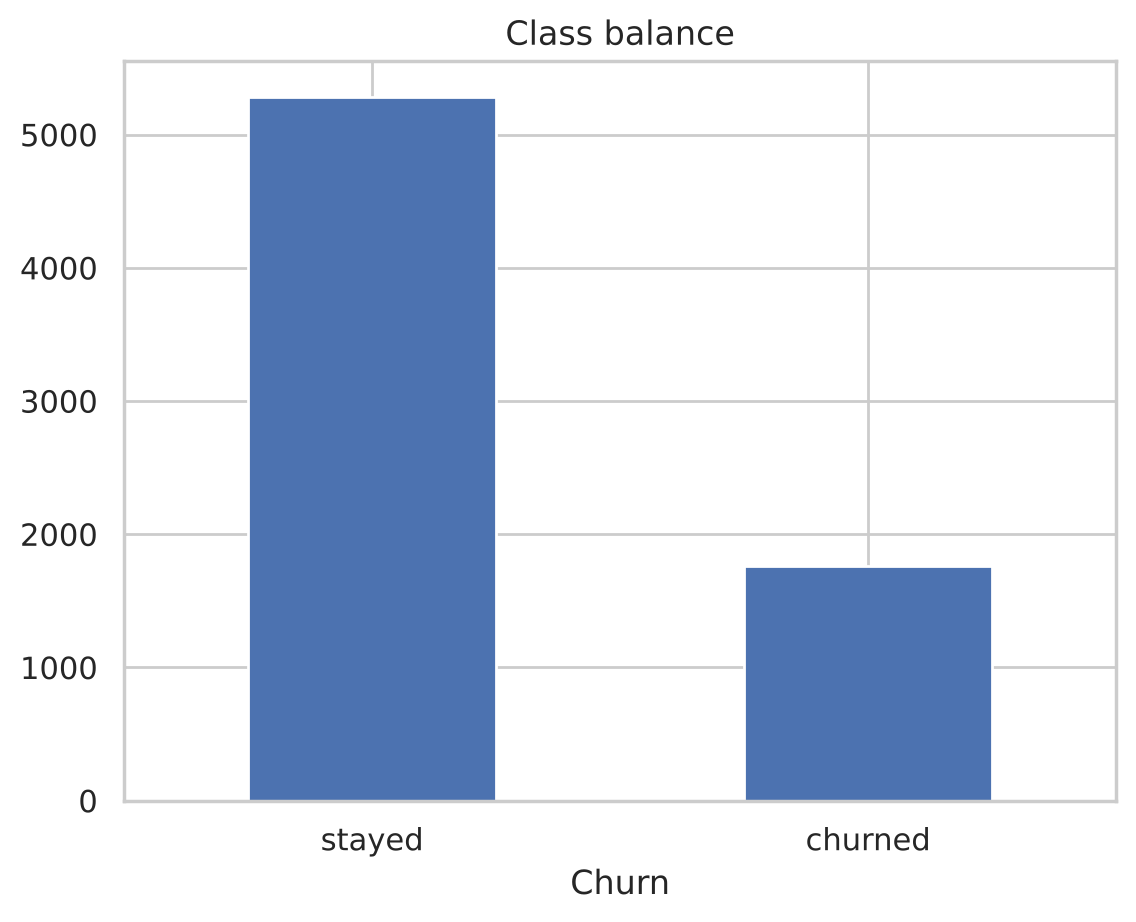

In [4]:
from features import clean, add_features
df = add_features(clean(raw))
print(df.shape, "| churn rate:", f"{df.Churn.mean():.1%}")
df.Churn.value_counts().rename({0: "stayed", 1: "churned"}).plot.bar(title="Class balance", rot=0); plt.show()

**Class imbalance:** ~25% churn. A model that predicts "nobody churns" is 75% accurate and useless, so accuracy is the wrong metric. We will use ROC-AUC, PR-AUC, precision and recall.

## Numeric features vs churn

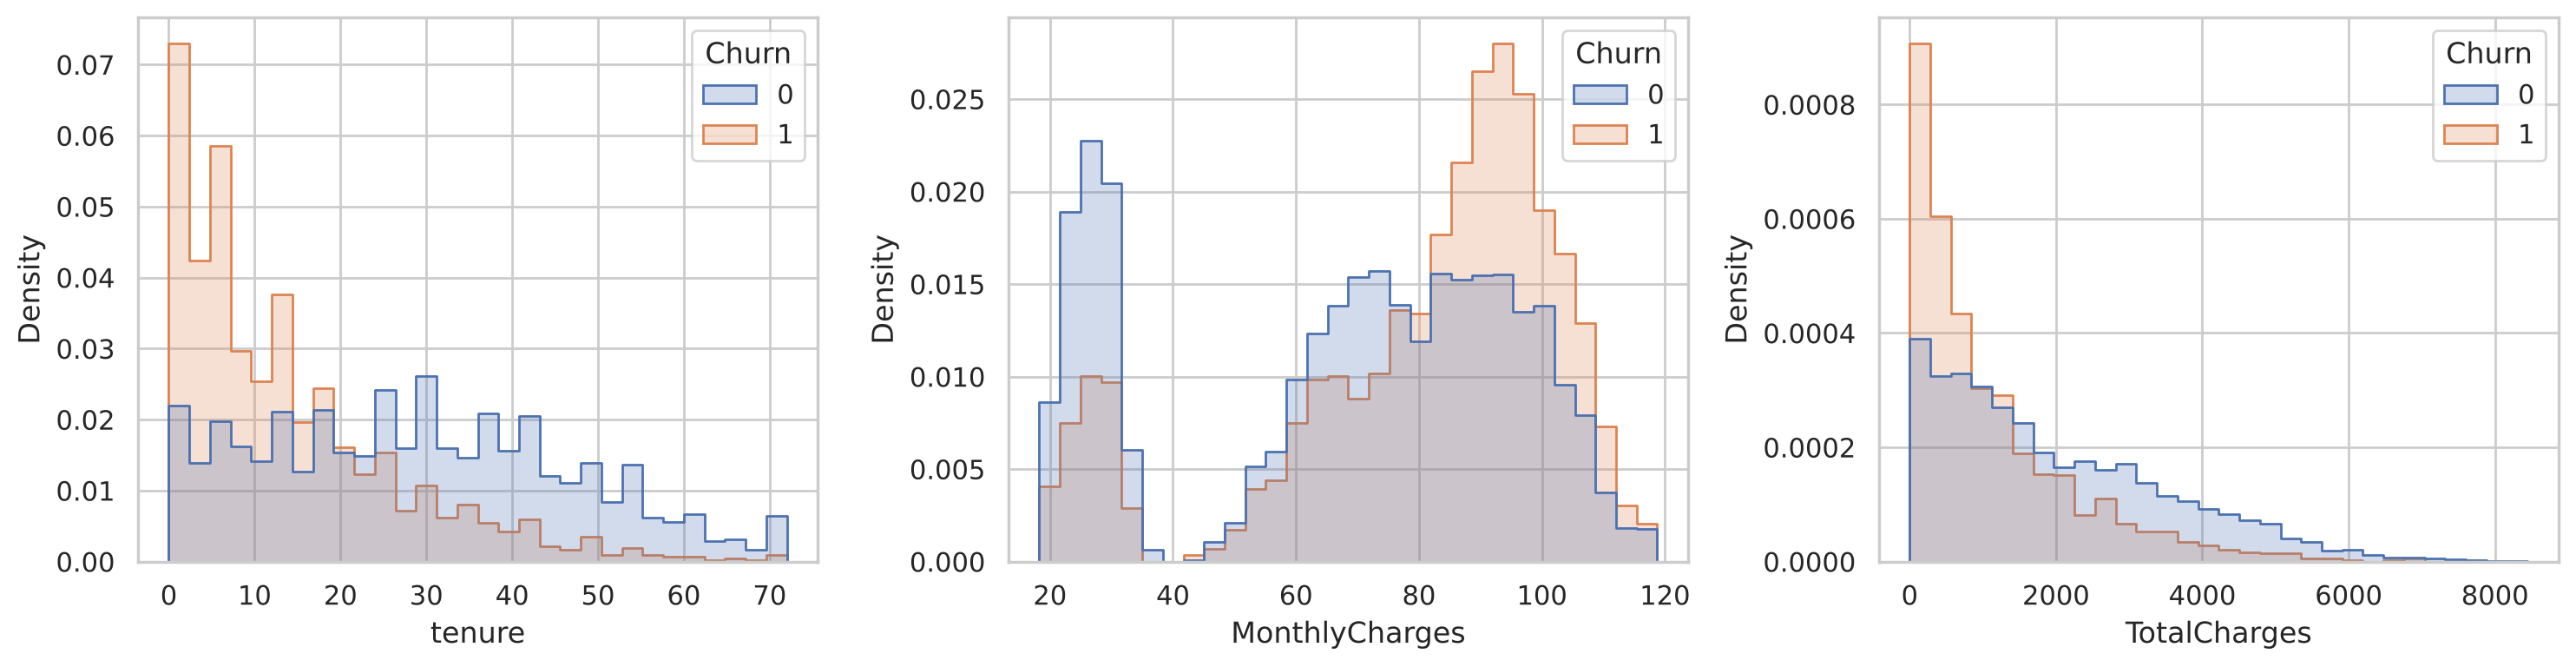

,tenure,MonthlyCharges,TotalCharges,num_addons
Churn,,,,
0,28.0,73.120,1578.570,2.0
1,10.0,87.495,715.025,2.0


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(df, x=col, hue="Churn", stat="density", common_norm=False, bins=30, ax=ax, element="step")
plt.tight_layout(); plt.show()
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges", "num_addons"]].median()

Churners are **new** (median tenure much lower) and pay **more per month**. TotalCharges is right-skewed, so the pipeline log-transforms the charge columns.

## Categorical features: churn rate by group

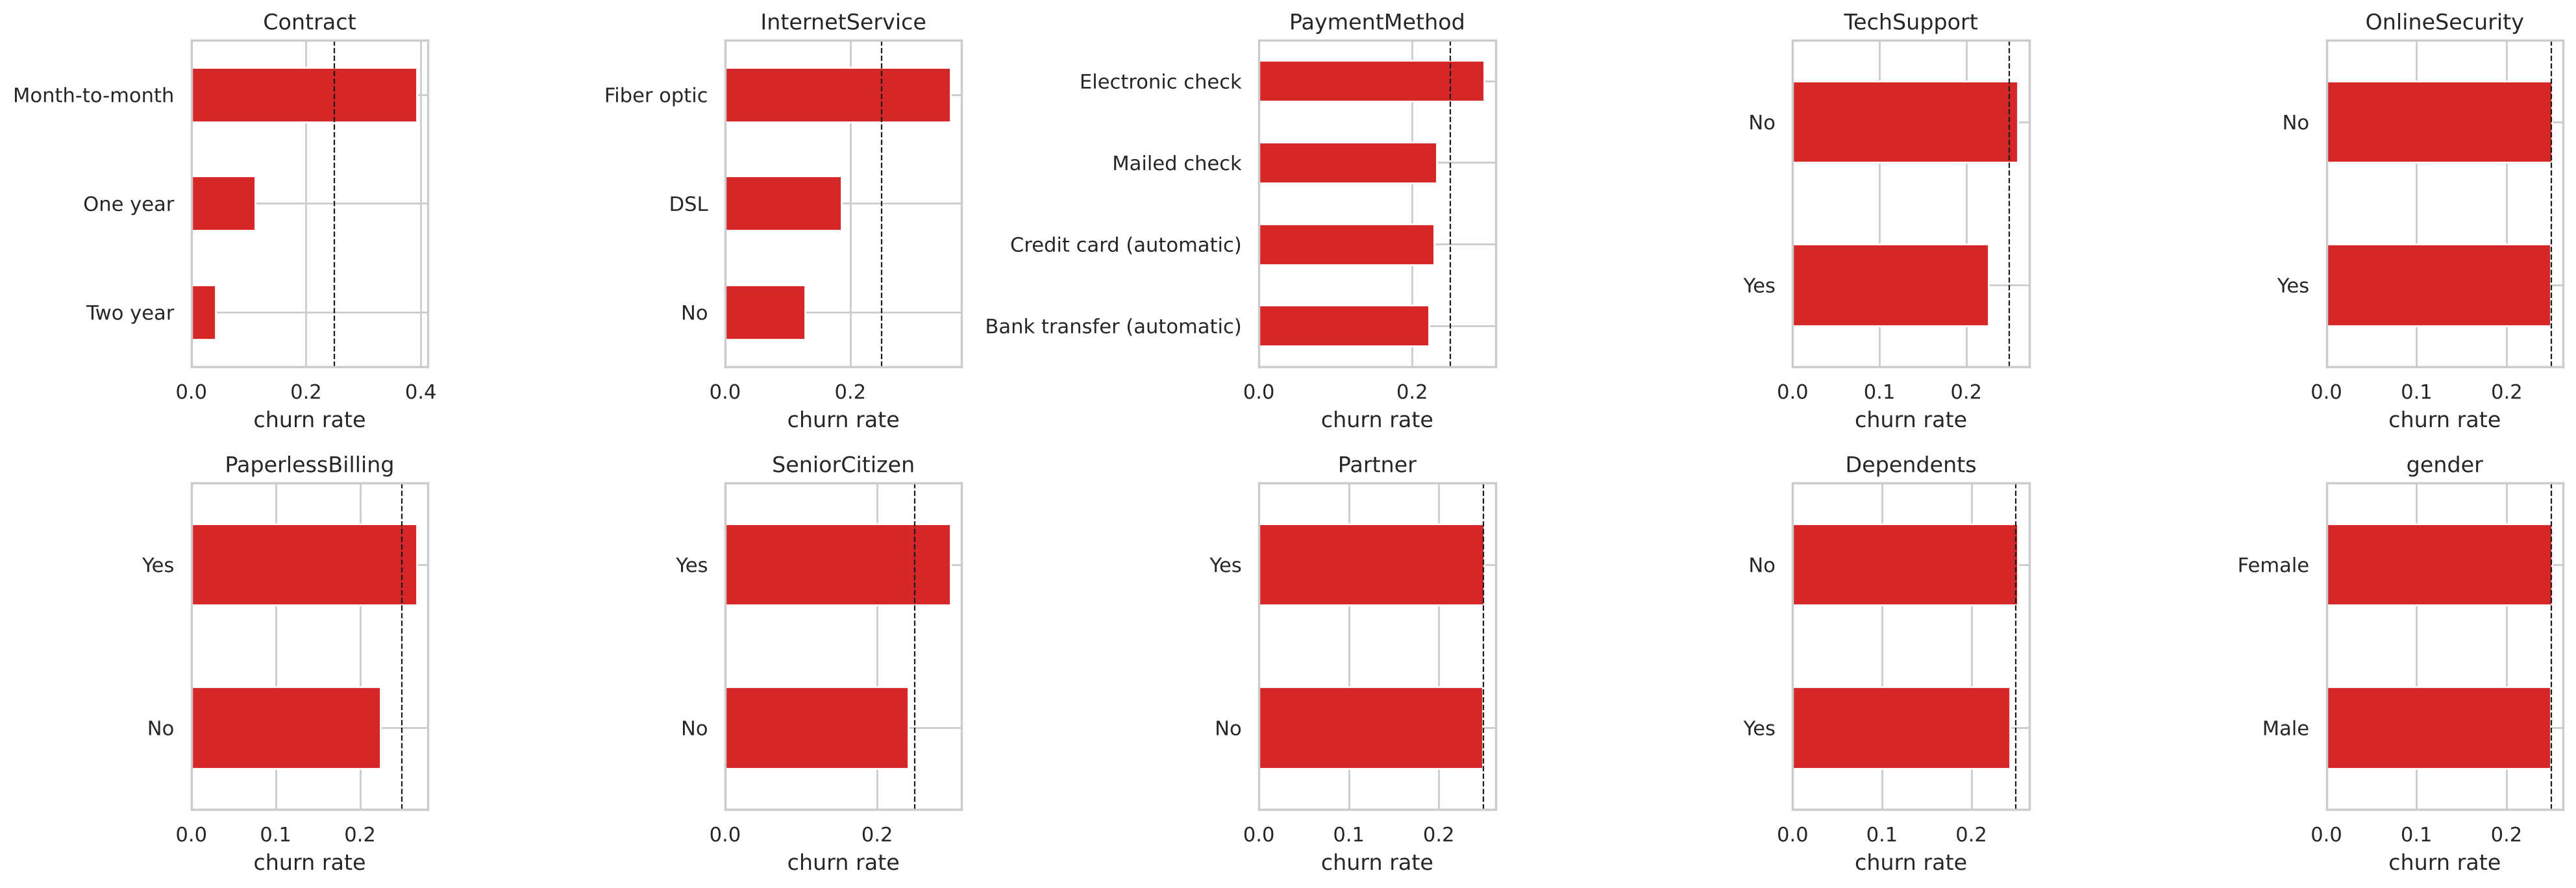

In [6]:
cats = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling",
        "SeniorCitizen", "Partner", "Dependents", "gender"]
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.flat, cats):
    rate = df.groupby(col).Churn.mean().sort_values()
    rate.plot.barh(ax=ax, color="tab:red"); ax.axvline(df.Churn.mean(), color="k", ls="--", lw=0.8)
    ax.set_title(col); ax.set_xlabel("churn rate"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Takeaways**
- **Contract** is the strongest single signal: month-to-month customers churn ~10× more than two-year customers.
- **Fibre optic**, **electronic cheque** and **paperless billing** go with higher churn.
- **Tech support** and **online security** go with lower churn.
- **Gender** makes no difference, which is good: the model should not lean on it.

## Correlation between numeric features

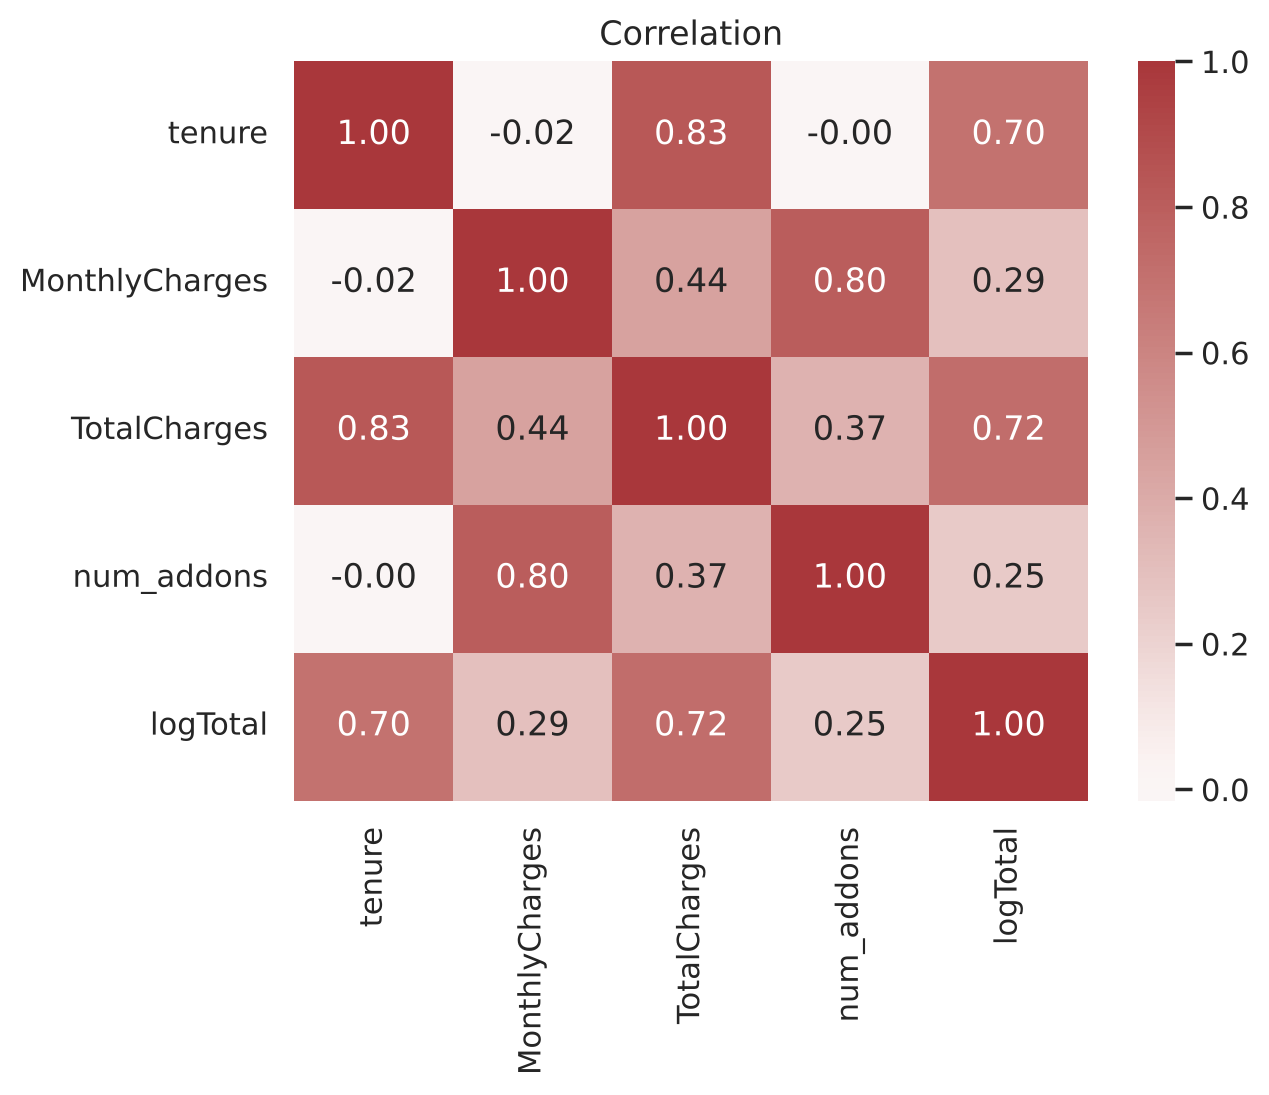

In [7]:
num = df[["tenure", "MonthlyCharges", "TotalCharges", "num_addons"]].assign(logTotal=np.log1p(df.TotalCharges))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="vlag", center=0); plt.title("Correlation"); plt.show()

`TotalCharges` ≈ `tenure × MonthlyCharges`, so it is strongly correlated with tenure. For logistic regression this **multicollinearity** doesn't hurt predictions, but it makes individual coefficients harder to read: tenure and TotalCharges can "share" the effect and even take opposite signs. We keep both (it helped validation score) and point this out when interpreting coefficients in notebook 02.

## Churn over the customer lifetime

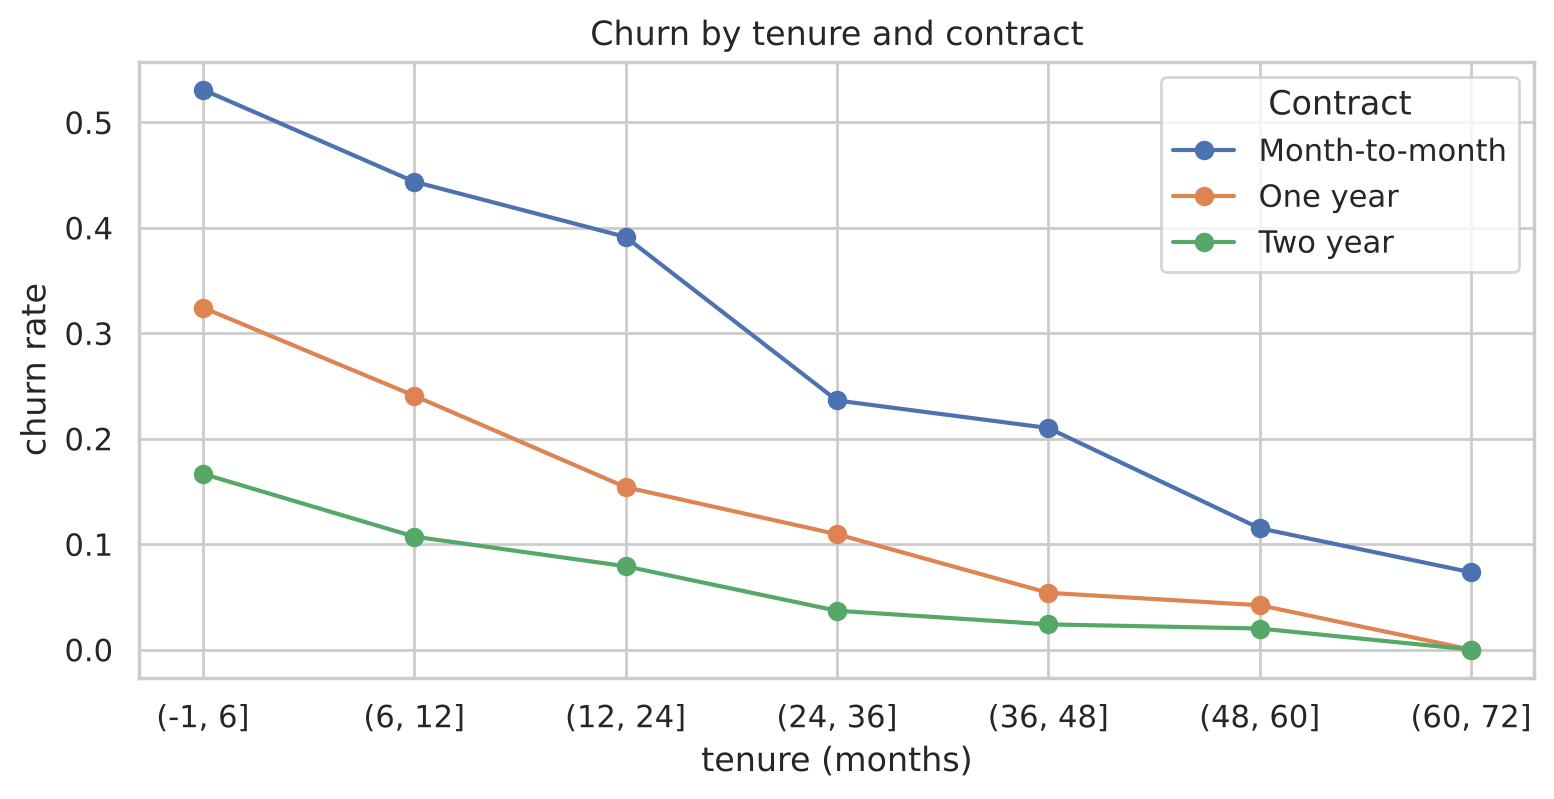

In [8]:
bins = pd.cut(df.tenure, [-1, 6, 12, 24, 36, 48, 60, 72])
df.groupby([bins, "Contract"], observed=True).Churn.mean().unstack().plot(marker="o", figsize=(9, 4))
plt.ylabel("churn rate"); plt.xlabel("tenure (months)"); plt.title("Churn by tenure and contract"); plt.show()

Risk is highest in the first 6 months and drops steadily. Month-to-month customers stay risky much longer, which hints at a **contract × tenure interaction** a plain linear model can only approximate. That is one reason the model won't be perfect.

**Next:** `02_train_evaluate.ipynb`.